# 01 · Dataset overview

Exploratory analysis of the challenge dataset: **4,982 Codeforces exercises**, each with
its problem statement, one accepted Python solution and its tags (the prediction target).

This notebook answers three questions:

1. **What is in the data?** Every variable: type, completeness, cardinality, meaning,
   availability at prediction time, and quirks.
2. **What does the target look like?** Tag frequencies, multi-label structure and
   co-occurrence, with a focus on the 8 tags named in the task statement (PROBLEM.md).
3. **Which inputs carry signal?** Statement text, sample I/O, solution code and metadata,
   and how each relates to the focus tags.

Shared code lives in `src/codeforces_tags/` (`data/`, `preprocessing/`, `near_duplicates/`, `analysis/`), and
every setting, such as the focus tags or the near-duplicate threshold, in `config.py`.
Raw samples go through `preprocess()` (typed columns, cleaned text, a `statement` column)
before analysis.
Background on the source dataset is in
[`docs/xcodeeval-paper-notes.md`](../docs/xcodeeval-paper-notes.md).
The [key takeaways](#9.-Key-takeaways) are at the end.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import roc_auc_score

from codeforces_tags.analysis.eda import (
    approximate_token_count,
    code_line_count,
    cooccurrence,
    cyrillic_field_counts,
    cyrillic_words,
    distinctive_terms,
    label_counts,
    lift,
    missing_value_counts,
    near_duplicate_summary,
    odds_ratio,
    parses_as_python3,
    profile_columns,
    scraping_artefact_shares,
    summarise_by_label,
    values_by_label,
    word_count,
)
from codeforces_tags.analysis.plotting import boxplot_by_label, focus_palette, setup_style
from codeforces_tags.config import (
    FOCUS_COLOR,
    FOCUS_TAGS,
    NEAR_DUPLICATE_CANDIDATE_THRESHOLD,
)
from codeforces_tags.data.labels import multi_hot
from codeforces_tags.data.loading import read_samples
from codeforces_tags.near_duplicates.detection import near_duplicate_groups
from codeforces_tags.preprocessing.pipeline import preprocess
from codeforces_tags.preprocessing.source_code import imported_modules, python_major_version
from codeforces_tags.preprocessing.text import (
    cyrillic_share,
    is_russian,
    math_spans,
    strip_latex,
)

setup_style()
pd.set_option("display.max_colwidth", 70)

raw = read_samples()  # values as stored in the JSON files
df = preprocess(raw)  # typed columns, cleaned text, `statement` and `python_version`
print(f"{len(raw):,} samples x {raw.shape[1]} variables")

4,982 samples x 21 variables


## 1. The variables

Every sample is one JSON file with 21 fields. The last column says whether the field can
be used as a model input for a new exercise.

| Group | Variable | Meaning | Usable at prediction time? |
|---|---|---|---|
| **Statement** | `prob_desc_description` | Statement text; math is wrapped in `$$$…$$$` (LaTeX) | yes |
| | `prob_desc_input_spec`, `prob_desc_output_spec` | Input and output format, with value ranges | yes |
| | `prob_desc_sample_inputs`, `prob_desc_sample_outputs` | Example tests, as a JSON-encoded list of strings | yes |
| | `prob_desc_notes` | Explanation of the examples (optional) | yes |
| | `prob_desc_time_limit`, `prob_desc_memory_limit` | Resource limits, as free text | yes |
| | `prob_desc_input_from`, `prob_desc_output_to` | I/O channel: standard streams or files | yes (near-constant) |
| | `prob_desc_created_at` | Release date, a Unix timestamp stored as a string | yes, but the tag mix drifts over time (§5) |
| **Solution** | `source_code` | One accepted Python solution | yes |
| | `lang` | Runtime: Python 2/3 or PyPy 2/3 | yes |
| | `lang_cluster` | Language family | no information (constant) |
| | `exec_outcome` | Judge verdict of the solution | no information (constant) |
| | `code_uid` | Submission id | no, identifier |
| | `file_name` | xCodeEval shard the sample was taken from | no, provenance |
| | `hidden_unit_tests` | Hidden judge tests | no information (always empty) |
| **Problem metadata** | `src_uid` | Problem id | no, identifier |
| | `difficulty` | Codeforces rating (800 = easiest, 3500 = hardest) | only if test inputs include it: it is set after the contest (§4) |
| | `tags` | **Target**: list of algorithmic tags | — |

The profile below is computed from the raw files. For `tags`, lists with the same tags
in a different order count as one value.

In [2]:
variables = profile_columns(raw)
variables

,value type,missing,empty,unique,example
variable,,,,,
prob_desc_time_limit,str,0,0,22,'2 seconds'
prob_desc_sample_outputs,str,0,0,4132,"'[""2\\n2 4\\n3 3\\n3 1""]'"
src_uid,str,0,0,4982,'591372383cf3624f69793c41370022de'
prob_desc_notes,str,1350,0,3596,"'NoteIn the first test case of the example, the optimal sequ"
prob_desc_description,str,0,0,4982,"""Numbers $$$1, 2, 3, \\dots n$$$ (each integer from $$$1$$$"
prob_desc_output_spec,str,85,0,4821,"'For each test case, in the first line, print the minimum po"
prob_desc_input_spec,str,33,0,4927,"""The first line contains one integer $$$t$$$ ($$$1 \\le t \\"
prob_desc_output_to,str,1,0,3,'standard output'
prob_desc_input_from,str,1,0,3,'standard input'


One complete sample, to see what a model receives. Long fields are cut.

In [3]:
sample = raw.loc[0]
for field in ["src_uid", "difficulty", "tags", "lang", "prob_desc_time_limit"]:
    print(f"{field:>22}: {sample[field]}")
statement_fields = [
    "prob_desc_description",
    "prob_desc_input_spec",
    "prob_desc_output_spec",
    "prob_desc_sample_inputs",
    "prob_desc_sample_outputs",
    "prob_desc_notes",
]
for field in statement_fields:
    print(f"\n--- {field}\n{str(sample[field])[:500]}")
code_head = "\n".join(sample["source_code"].splitlines()[:25])
print(f"\n--- source_code (first 25 lines)\n{code_head}")

               src_uid: 591372383cf3624f69793c41370022de
            difficulty: 1000.0
                  tags: ['greedy', 'constructive algorithms', 'math', 'implementation', 'data structures']
                  lang: Python 3
  prob_desc_time_limit: 2 seconds

--- prob_desc_description
Numbers $$$1, 2, 3, \dots n$$$ (each integer from $$$1$$$ to $$$n$$$ once) are written on a board. In one operation you can erase any two numbers $$$a$$$ and $$$b$$$ from the board and write one integer $$$\frac{a + b}{2}$$$ rounded up instead.You should perform the given operation $$$n - 1$$$ times and make the resulting number that will be left on the board as small as possible. For example, if $$$n = 4$$$, the following course of action is optimal:  choose $$$a = 4$$$ and $$$b = 2$$$, so the 

--- prob_desc_input_spec
The first line contains one integer $$$t$$$ ($$$1 \le t \le 1000$$$) — the number of test cases. The only line of each test case contains one integer $$$n$$$ ($$$2 \le n \le 2 \cdot 10

## 2. Data quality

### 2.1 Missing values

Three kinds of missing: `None`, an empty string or list, and the `-1` sentinel that
`difficulty` uses for unknown ratings.

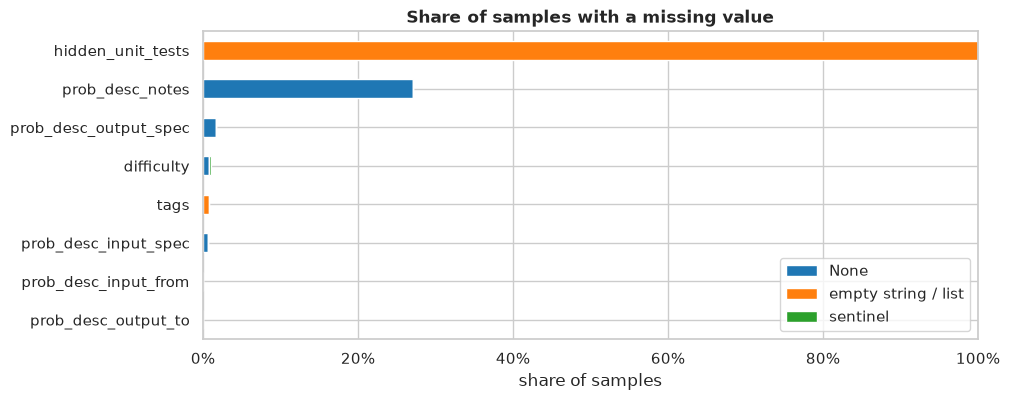

,None,empty string / list,sentinel,total,share
prob_desc_output_to,1,0,0,1,0.0002
prob_desc_input_from,1,0,0,1,0.0002
prob_desc_input_spec,33,0,0,33,0.0066
tags,0,41,0,41,0.0082
difficulty,39,0,15,54,0.0108
prob_desc_output_spec,85,0,0,85,0.0171
prob_desc_notes,1350,0,0,1350,0.2710
hidden_unit_tests,0,4982,0,4982,1.0000


In [4]:
missing = missing_value_counts(raw, sentinels={"difficulty": -1})

ax = (missing / len(raw)).plot.barh(stacked=True, figsize=(10, 4))
ax.legend(loc="lower right")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(title="Share of samples with a missing value", xlabel="share of samples", ylabel="")
plt.show()
missing.assign(total=missing.sum(axis=1), share=(missing.sum(axis=1) / len(raw)).round(4))

### 2.2 Constant and near-constant variables

A variable with a single value carries no information for the model.

In [5]:
display(variables.loc[variables["unique"] <= 1, ["unique", "example"]])
for column in ["prob_desc_input_from", "prob_desc_output_to"]:
    display(raw[column].value_counts(dropna=False).rename_axis(column).to_frame("samples"))

,unique,example
variable,,
lang_cluster,1,'Python'
exec_outcome,1,'PASSED'
hidden_unit_tests,1,''


,samples
prob_desc_input_from,
standard input,4933
input.txt,32
стандартный ввод,16
NaN,1


,samples
prob_desc_output_to,
standard output,4933
output.txt,32
стандартный вывод,16
NaN,1


### 2.3 Identifiers and provenance

In [6]:
pd.Series(
    {
        "samples": len(raw),
        "distinct problems (src_uid)": raw["src_uid"].nunique(),
        "distinct submissions (code_uid)": raw["code_uid"].nunique(),
        "distinct statements": raw["prob_desc_description"].nunique(),
        "distinct solutions": raw["source_code"].nunique(),
        "xCodeEval shards (file_name)": raw["file_name"].nunique(),
        "samples from train_*.jsonl shards": raw["file_name"].str.startswith("train_").sum(),
    },
    name="count",
).to_frame()

,count
samples,4982
distinct problems (src_uid),4982
distinct submissions (code_uid),4982
distinct statements,4982
distinct solutions,4982
xCodeEval shards (file_name),111
samples from train_*.jsonl shards,4982


Exact duplicates do not exist, but near-duplicates do (§2.6).

### 2.4 Text in Russian

Some problems were scraped from the Russian version of Codeforces. A field is counted as
Russian when most of its letters are Cyrillic. A single Cyrillic letter is usually a
look-alike typed inside English text (`С++` with a Cyrillic `С`), which a tokenizer would
split oddly. `preprocess()` replaces these look-alikes and leaves Russian text as is.

In [7]:
display(cyrillic_field_counts(raw))

russian = raw["prob_desc_description"].map(is_russian)
russian_limits = raw["prob_desc_time_limit"].map(is_russian)
print(
    f"{russian.sum()} statements are in Russian and {russian_limits.sum()} problems have "
    f"their limits in Russian; {(russian & russian_limits).sum()} problems have both."
)
has_cyrillic = raw["prob_desc_description"].map(cyrillic_share) > 0
look_alikes = raw.loc[has_cyrillic & ~russian, "prob_desc_description"]
look_alikes.map(cyrillic_words).head(6).rename("words with Cyrillic look-alike letters").to_frame()

,any Cyrillic letter,mostly Cyrillic (Russian)
prob_desc_description,31,17
prob_desc_input_spec,52,17
prob_desc_output_spec,66,17
prob_desc_notes,18,10


17 statements are in Russian and 17 problems have their limits in Russian; 17 problems have both.


,words with Cyrillic look-alike letters
sample_id,
266,[А]
293,[Сommand]
345,[Т]
758,[оf]
1769,[simplе]
1809,[с]


### 2.5 Scraping artefacts

The statements were scraped from HTML, and a few traces remain:

- paragraphs are concatenated without a space (`…rounded up instead.You should…`),
  so naive whitespace tokenisation glues words together;
- the notes keep their section heading glued to the text (`NoteIn the first test…`);
- a few tag lists contain the same tag twice.

`preprocess()` fixes all three: it restores the missing space, removes the notes heading
and drops repeated tags. The table compares the raw data with the preprocessed data. A
heading counts as glued when the next word follows it directly, so a sentence starting
with "Note that…" is not counted.

In [8]:
before_after = pd.DataFrame(
    {"raw": scraping_artefact_shares(raw), "preprocessed": scraping_artefact_shares(df)}
)
display(before_after.map("{:.1%}".format))
before = raw.loc[0, "prob_desc_description"]
at = before.index("instead.")
print("Before:", before[at - 20 : at + 30])
print("After: ", df.loc[0, "prob_desc_description"][at - 20 : at + 31])

,raw,preprocessed
statements with a glued paragraph break,85.9%,0.0%
notes with a heading glued to the text,98.7%,0.0%
problems with a repeated tag,0.2%,0.0%


Before: b}{2}$$$ rounded up instead.You should perform the
After:  b}{2}$$$ rounded up instead. You should perform the


### 2.6 Near-duplicate statements

Codeforces often publishes an *easy* and a *hard* version of the same problem with
near-identical statements. A random train/test split would put one version on each side
and inflate the test score, so splits must keep each group together.
`near_duplicate_groups()` finds the groups in two stages. Statements whose TF-IDF cosine
similarity reaches `NEAR_DUPLICATE_CANDIDATE_THRESHOLD` (0.4, in `config.py`) become
candidates, then the frozen verdicts of two blind LLM judges keep the true duplicates. Both stages
are audited in [`02_near_duplicates.ipynb`](02_near_duplicates.ipynb).

In [9]:
groups = near_duplicate_groups(df)
print(f"Candidates: TF-IDF similarity >= {NEAR_DUPLICATE_CANDIDATE_THRESHOLD}, then judged")
group_size = groups.map(groups.value_counts())
twins = df.loc[group_size > 1, ["tags", "prob_desc_description"]].assign(group=groups)
mentions_version = df["prob_desc_description"].str.contains(
    r"\b(?:easy|hard)(?:er)? version", case=False
)

summary = near_duplicate_summary(groups, df["tags"])
summary["grouped statements mentioning an easy/hard version"] = mentions_version[twins.index].sum()
print(f"{summary['problems in a group'] / len(df):.1%} of problems are in a group")
summary.to_frame("value")

Candidates: TF-IDF similarity >= 0.4, then judged
3.3% of problems are in a group


,value
groups of near-duplicates,82
largest group size,2
problems in a group,164
groups with identical tags,19
groups with identical focus tags,69
grouped statements mentioning an easy/hard version,101


In [10]:
for _, pair in list(twins.groupby("group"))[:3]:
    for sample_id, row in pair.iterrows():
        print(f"[{sample_id}] {sorted(row['tags'])}")
        print(f"    {strip_latex(row['prob_desc_description'])[:150]}…")
    print()

[56] ['binary search', 'brute force', 'constructive algorithms', 'greedy', 'sortings', 'two pointers']
    This is the hard version of the problem. The difference between the versions is that in the easy version all prices   are different. You can make hack…
[726] ['binary search', 'constructive algorithms', 'greedy', 'sortings']
    This is the easy version of the problem. The difference between the versions is that in the easy version all prices   are different. You can make hack…

[240] ['data structures', 'implementation']
    Vova's family is building the Great Vova Wall (named by Vova himself). Vova's parents, grandparents, grand-grandparents contributed to it. Now it's to…
[1307] ['greedy', 'implementation', 'math']
    Vova's family is building the Great Vova Wall (named by Vova himself). Vova's parents, grandparents, grand-grandparents contributed to it. Now it's to…

[342] ['strings']
    This problem is different from the easy version. In this version Ujan makes at most   sw

## 3. The target: tags

### 3.1 Problems without tags

41 problems have an empty tag list. They stay in the dataset, where they count as
problems with none of the tags. Some of them are clearly about trees, graphs or games,
though, so their labels may be incomplete: keep this in mind when reading the model's
errors on them.

In [11]:
untagged = df[df["tags"].str.len() == 0]
topical = untagged["prob_desc_description"].str.contains(r"\b(?:tree|graph|game)", case=False)
for sample_id, text in untagged.loc[topical, "prob_desc_description"].head(4).items():
    print(f"[{sample_id}] {strip_latex(text)[:160]}…")

years = untagged["prob_desc_created_at"].dt.year
share = len(untagged) / len(df)
print(f"\n{len(untagged)} problems without tags ({share:.1%}),", end=" ")
print(f"released {years.min()}-{years.max()}")

[1080] Heidi has finally found the mythical Tree of Life – a legendary combinatorial structure which is said to contain a prophecy crucially needed to defeat the undea…
[2630] A tree of size n is an undirected connected graph consisting of n vertices without cycles. Consider some tree with n vertices. We call a tree invariant relative…
[3447] Heidi got one brain, thumbs up! But the evening isn't over yet and one more challenge awaits our dauntless agent: after dinner, at precisely midnight, the N att…
[3587] Limak is a little bear who learns to draw. People usually start with houses, fences and flowers but why would bears do it? Limak lives in the forest and he deci…

41 problems without tags (0.8%), released 2012-2021


### 3.2 Tag frequencies

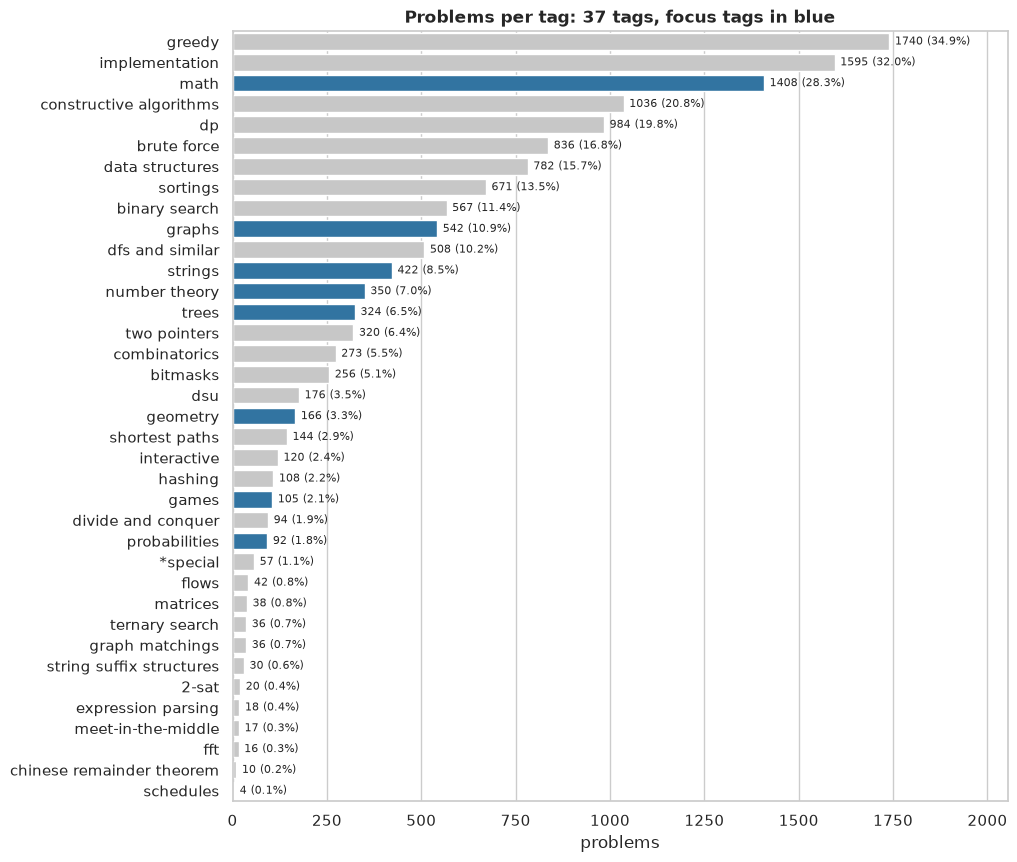

In [12]:
tag_freq = label_counts(df["tags"])

fig, ax = plt.subplots(figsize=(10, 10))
sns.barplot(
    x=tag_freq.values,
    y=tag_freq.index,
    hue=tag_freq.index,
    palette=dict(zip(tag_freq.index, focus_palette(tag_freq.index), strict=True)),
    legend=False,
    ax=ax,
)
for position, count in enumerate(tag_freq):
    label = f"{count} ({count / len(df):.1%})"
    ax.text(count + 15, position, label, va="center", fontsize=8)
ax.set(title=f"Problems per tag: {len(tag_freq)} tags, focus tags in blue", xlabel="problems")
ax.set(ylabel="", xlim=(0, tag_freq.max() * 1.18))
plt.show()

The xCodeEval paper's tag-distribution figure lists 31 tags. Our subset has more:

In [13]:
PAPER_FIGURE_8_TAGS = {
    "2-sat", "binary search", "bitmasks", "brute force", "combinatorics",
    "constructive algorithms", "data structures", "dfs and similar", "divide and conquer",
    "dp", "dsu", "expression parsing", "fft", "flows", "games", "geometry",
    "graph matchings", "graphs", "greedy", "implementation", "interactive", "math",
    "matrices", "meet-in-the-middle", "number theory", "probabilities", "shortest paths",
    "sortings", "strings", "trees", "two pointers",
}  # fmt: skip
extra_tags = tag_freq.index.difference(sorted(PAPER_FIGURE_8_TAGS))
tag_freq[extra_tags].sort_values(ascending=False).to_frame()

,problems
tags,
hashing,108
*special,57
ternary search,36
string suffix structures,30
chinese remainder theorem,10
schedules,4


### 3.3 Multi-label structure

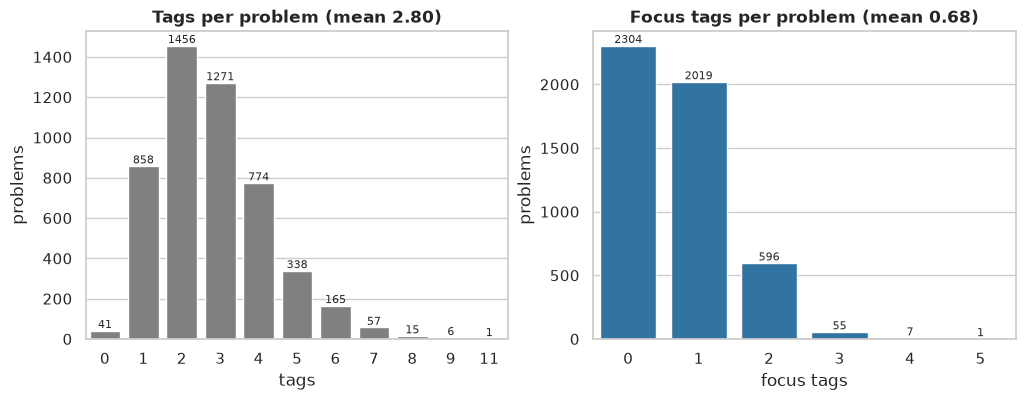

,value
problems without any tag,41 (0.8%)
problems without a focus tag,2304 (46.2%)
problems with 2+ focus tags,659 (13.2%)
distinct tag sets,1722


In [14]:
focus = multi_hot(df["tags"], vocabulary=FOCUS_TAGS)
n_tags = df["tags"].str.len()
n_focus = focus.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=n_tags, color="grey", ax=axes[0])
axes[0].set(title=f"Tags per problem (mean {n_tags.mean():.2f})", xlabel="tags")
sns.countplot(x=n_focus, color=FOCUS_COLOR, ax=axes[1])
axes[1].set(title=f"Focus tags per problem (mean {n_focus.mean():.2f})", xlabel="focus tags")
for ax in axes:
    ax.bar_label(ax.containers[0], fontsize=8)
    ax.set(ylabel="problems")
plt.show()

pd.Series(
    {
        "problems without any tag": f"{(n_tags == 0).sum()} ({(n_tags == 0).mean():.1%})",
        "problems without a focus tag": f"{(n_focus == 0).sum()} ({(n_focus == 0).mean():.1%})",
        "problems with 2+ focus tags": f"{(n_focus >= 2).sum()} ({(n_focus >= 2).mean():.1%})",
        "distinct tag sets": df["tags"].map(frozenset).nunique(),
    },
    name="value",
).to_frame()

### 3.4 The 8 focus tags

In [15]:
focus_summary = pd.DataFrame({"problems": focus.sum(), "share": focus.mean().round(3)})
focus_summary = focus_summary.sort_values("problems", ascending=False)
rarest = focus_summary["problems"].min()
focus_summary["ratio to rarest"] = (focus_summary["problems"] / rarest).round(1)
order = focus_summary.index
focus_summary

,problems,share,ratio to rarest
label,,,
math,1408,0.283,15.3
graphs,542,0.109,5.9
strings,422,0.085,4.6
number theory,350,0.070,3.8
trees,324,0.065,3.5
geometry,166,0.033,1.8
games,105,0.021,1.1
probabilities,92,0.018,1.0


### 3.5 Co-occurrence

Cell (row, column) is the share of problems tagged *row* that are also tagged *column*.
The diagonal is 100% by construction.

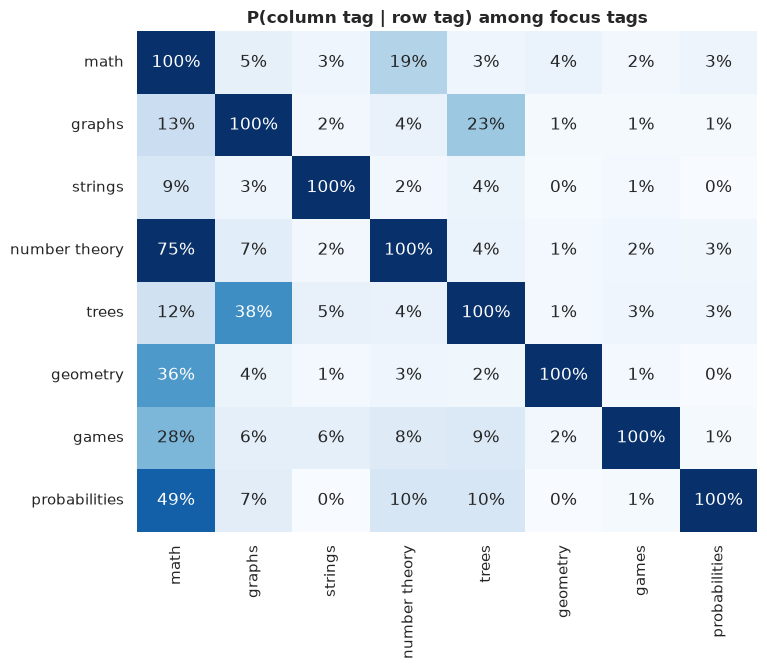

In [16]:
conditional = cooccurrence(focus, normalize=True).loc[order, order]

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(conditional, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=0.6, cbar=False)
ax.set(title="P(column tag | row tag) among focus tags", xlabel="", ylabel="")
plt.show()

**Which other tags travel with each focus tag?** The same reading, with the 20 most
frequent tags as columns. It shows each focus tag's neighbourhood, and which non-focus
tags could serve as extra supervision.

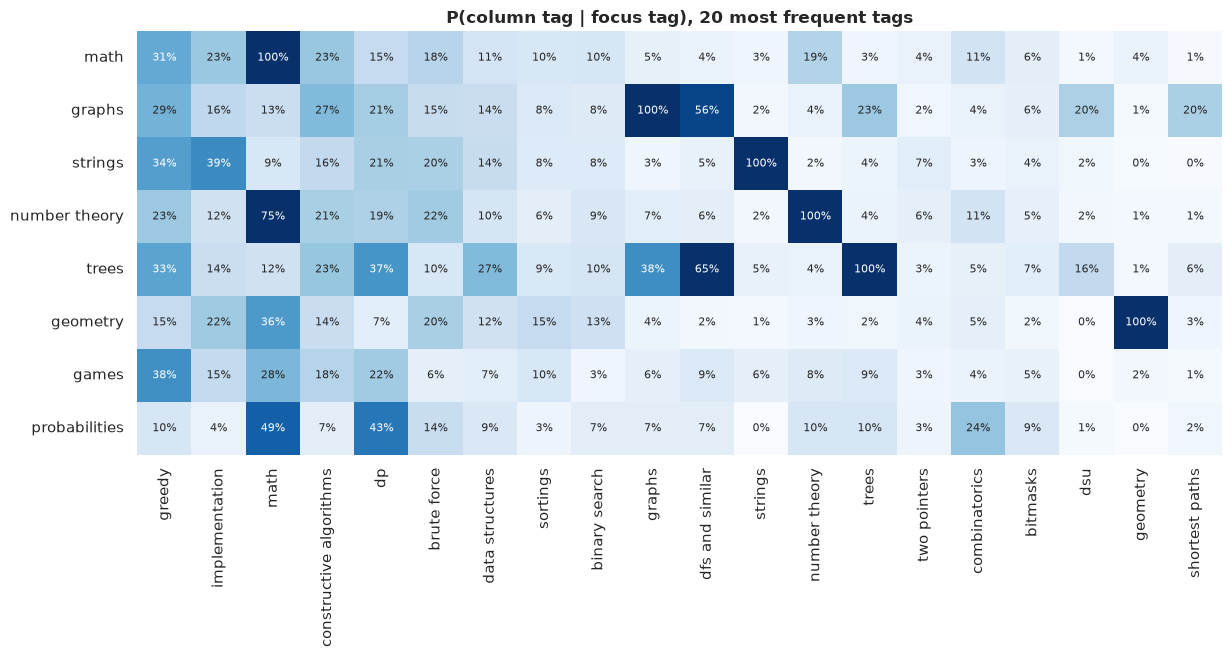

In [17]:
top_tags = multi_hot(df["tags"], vocabulary=tag_freq.index[:20])
focus_given = cooccurrence(focus, top_tags, normalize=True).loc[order]

fig, ax = plt.subplots(figsize=(14, 5.5))
sns.heatmap(
    focus_given, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=0.6, cbar=False,
    annot_kws={"fontsize": 8}, ax=ax,
)  # fmt: skip
ax.set(title="P(column tag | focus tag), 20 most frequent tags", xlabel="", ylabel="")
plt.show()

## 4. Difficulty

Codeforces ratings go from 800 to 3500 in steps of 100. Missing ratings (`None` and
`-1`) are `NA` after `preprocess()`. The rating is assigned after the contest, from how
many contestants solved the problem. It is a legitimate input only if the test
exercises come with it.

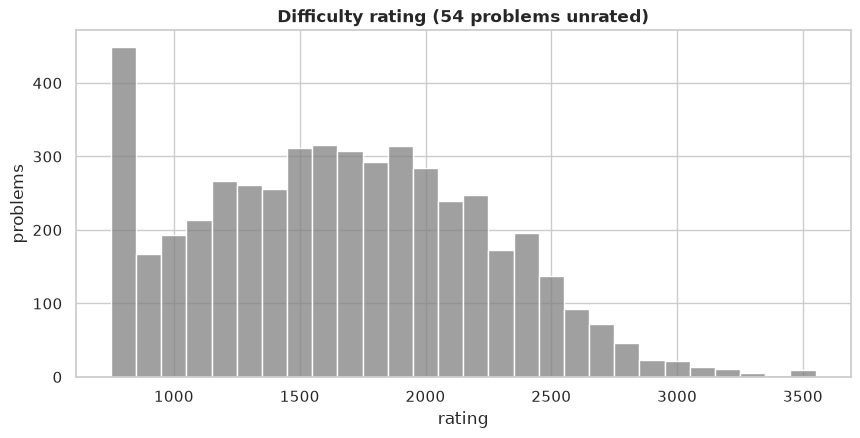

,count,mean,std,min,25%,50%,75%,max
difficulty,4928.0,1673.0,562.0,800.0,1200.0,1700.0,2100.0,3500.0


In [18]:
difficulty = df["difficulty"].astype("float")

fig, ax = plt.subplots()
sns.histplot(difficulty.dropna(), bins=np.arange(750, 3600, 100), color="grey", ax=ax)
unrated = difficulty.isna().sum()
ax.set(title=f"Difficulty rating ({unrated} problems unrated)", xlabel="rating")
ax.set(ylabel="problems")
plt.show()
difficulty.describe().round(0).to_frame().T

Distribution per focus tag. A problem with several focus tags appears in each of their
boxes; problems with no focus tag form their own box.

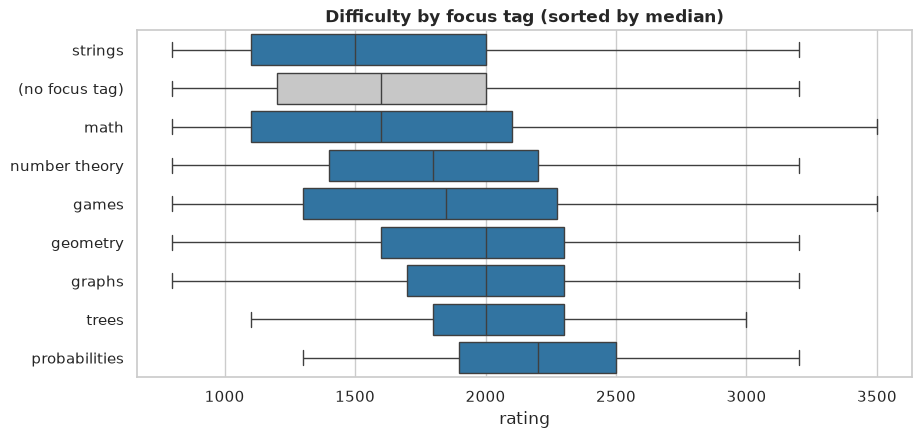

In [19]:
NO_FOCUS = "(no focus tag)"


ax = boxplot_by_label(difficulty, focus, none_label=NO_FOCUS)
ax.set(title="Difficulty by focus tag (sorted by median)", xlabel="rating")
plt.show()

How well does difficulty alone separate each tag? ROC AUC of the rating as a score
(0.5 = no information; below 0.5 = the tag is more common among easy problems).

In [20]:
rated = difficulty.notna()
pd.Series(
    {tag: roc_auc_score(focus.loc[rated, tag], difficulty[rated]) for tag in order},
    name="ROC AUC of difficulty",
).round(2).to_frame().T

,math,graphs,strings,number theory,trees,geometry,games,probabilities
ROC AUC of difficulty,0.47,0.7,0.44,0.56,0.72,0.63,0.56,0.79


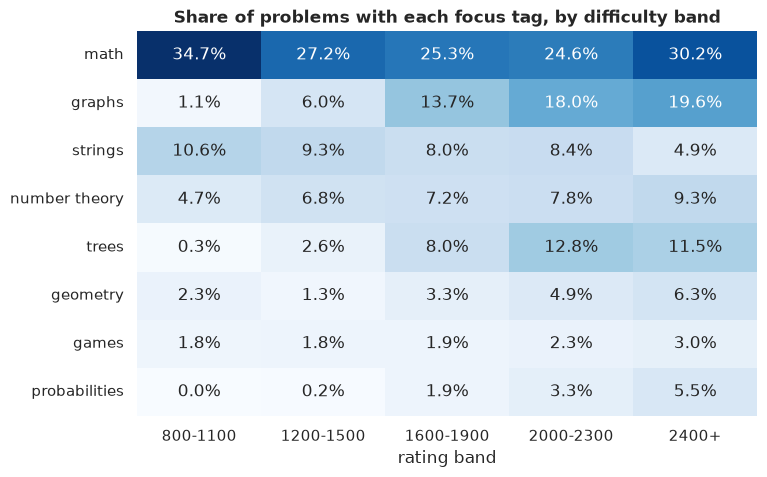

difficulty,800-1100,1200-1500,1600-1900,2000-2300,2400+
problems,1023.00,1096.00,1230.00,946.00,633.00
mean tags,2.05,2.57,2.94,3.34,3.35
mean focus tags,0.55,0.55,0.69,0.82,0.90


In [21]:
bands = pd.cut(
    difficulty,
    bins=[0, 1199, 1599, 1999, 2399, 4000],
    labels=["800-1100", "1200-1500", "1600-1900", "2000-2300", "2400+"],
)
prevalence_by_band = focus.groupby(bands, observed=True).mean().T.loc[order]

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(prevalence_by_band, annot=True, fmt=".1%", cmap="Blues", cbar=False, ax=ax)
ax.set(title="Share of problems with each focus tag, by difficulty band", ylabel="")
ax.set(xlabel="rating band")
plt.show()

pd.DataFrame(
    {
        "problems": bands.value_counts().sort_index(),
        "mean tags": n_tags.groupby(bands, observed=True).mean(),
        "mean focus tags": n_focus.groupby(bands, observed=True).mean(),
    }
).round(2).T

## 5. Release date

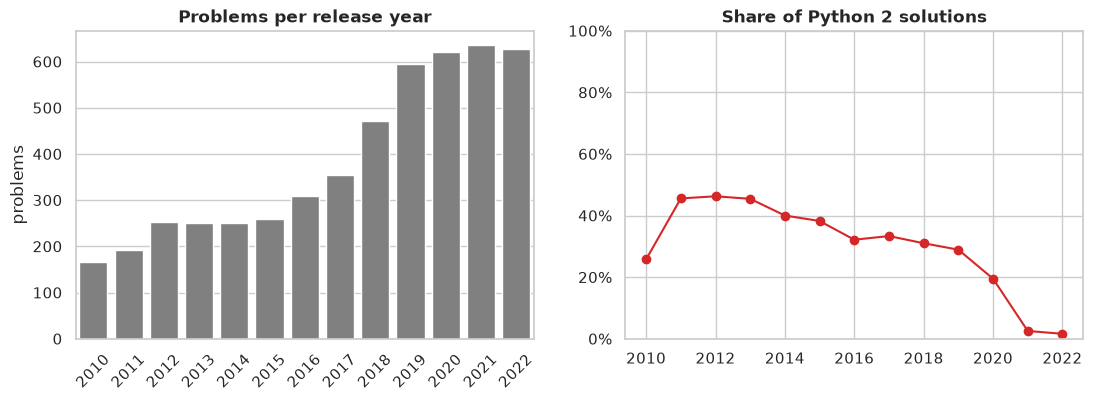

Release dates: 2010-02-19 to 2022-11-21
Python 2 share: 24.9% overall, 45.8% for 2011-2013, 2.1% from 2021


In [22]:
year = df["prob_desc_created_at"].dt.year
python_major = df["python_version"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=year, color="grey", ax=axes[0])
axes[0].set(title="Problems per release year", xlabel="", ylabel="problems")
axes[0].tick_params(axis="x", rotation=45)
(python_major == 2).groupby(year).mean().plot(marker="o", ax=axes[1], color="tab:red")
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].set(title="Share of Python 2 solutions", xlabel="", ylabel="", ylim=(0, 1))
plt.show()

first, last = df["prob_desc_created_at"].agg(["min", "max"])
print(f"Release dates: {first:%Y-%m-%d} to {last:%Y-%m-%d}")
print(f"Python 2 share: {(python_major == 2).mean():.1%} overall, "
      f"{(python_major[year.between(2011, 2013)] == 2).mean():.1%} for 2011-2013, "
      f"{(python_major[year >= 2021] == 2).mean():.1%} from 2021")  # fmt: skip

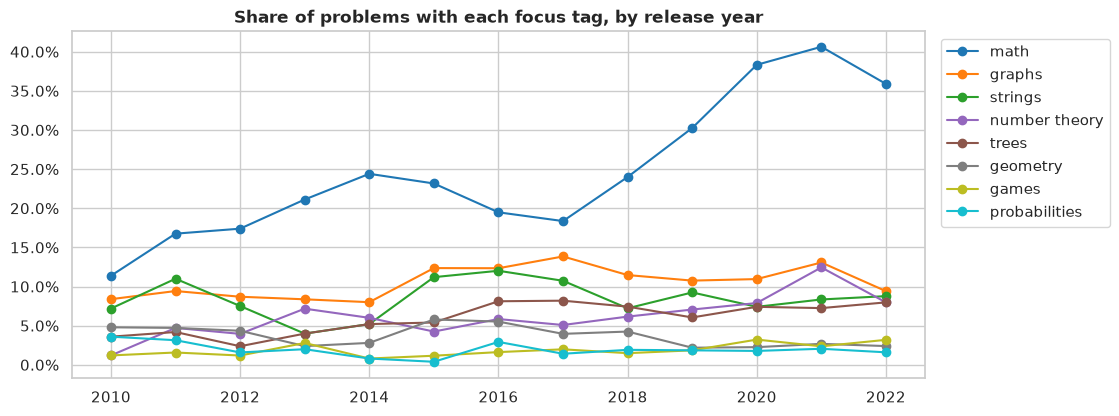

math share: 19.4% up to 2017, 36.4% from 2019


In [23]:
fig, ax = plt.subplots(figsize=(11, 4.5))
focus.groupby(year).mean()[order].plot(marker="o", ax=ax, colormap="tab10")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(title="Share of problems with each focus tag, by release year", xlabel="", ylabel="")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()
math_share = focus["math"].groupby(year <= 2017).mean()
print(f"math share: {math_share[True]:.1%} up to 2017, "
      f"{focus['math'][year >= 2019].mean():.1%} from 2019")  # fmt: skip

## 6. Resource limits

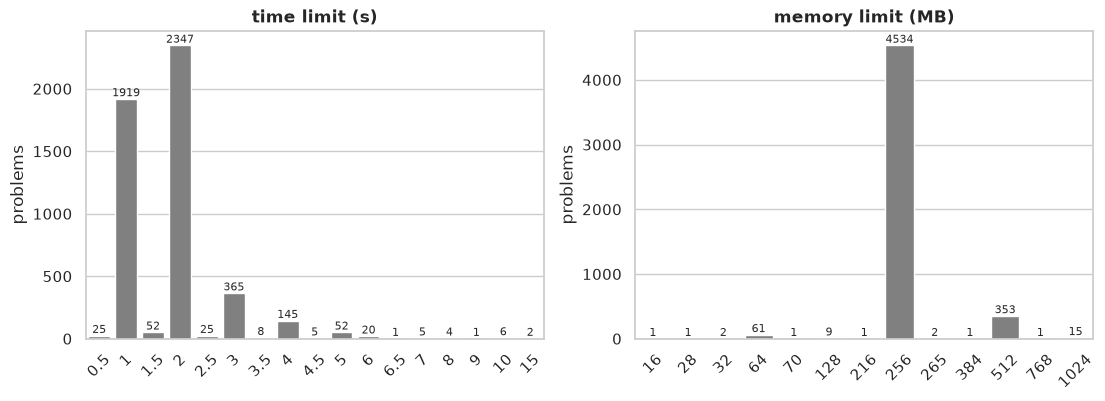

Unparsed limits: {'time_limit_s': 0, 'memory_limit_mb': 0}


,math,graphs,strings,number theory,trees,geometry,games,probabilities,all problems
time_limit_s,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
memory_limit_mb,256.0,256.0,256.0,256.0,256.0,256.0,256.0,256.0,256.0


In [24]:
limits = {"time_limit_s": "time limit (s)", "memory_limit_mb": "memory limit (MB)"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (column, label) in zip(axes, limits.items(), strict=True):
    counts = df[column].value_counts().sort_index()
    sns.barplot(x=counts.index.map("{:g}".format), y=counts.values, color="grey", ax=ax)
    ax.bar_label(ax.containers[0], fontsize=8)
    ax.set(title=label, xlabel="", ylabel="problems")
    ax.tick_params(axis="x", rotation=45)
plt.show()

print("Unparsed limits:", df[list(limits)].isna().sum().to_dict())
summarise_by_label(df[list(limits)], focus[order], "median")

86% of problems have a 1 s or 2 s time limit and 91% have 256 MB of memory. The median
limits are the same (2 s, 256 MB) for every focus tag, so the limits are not worth a
feature.

## 7. Problem statement

### 7.1 Length of each text field

Word counts after removing the `$$$…$$$` math spans, over the problems where the field
is present.

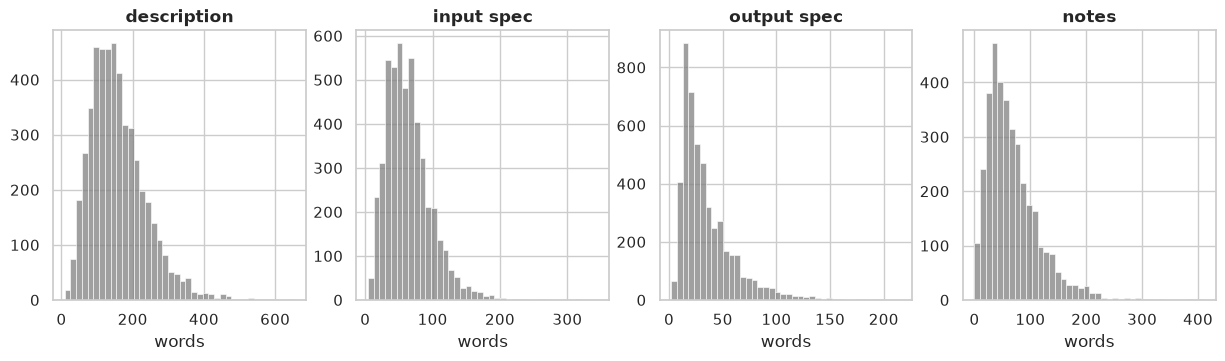

,count,mean,std,min,5%,50%,95%,max
description,4982.0,159.0,78.0,9.0,56.0,146.0,301.0,654.0
input spec,4949.0,65.0,35.0,4.0,20.0,59.0,125.0,345.0
output spec,4897.0,35.0,26.0,2.0,10.0,27.0,87.0,216.0
notes,3632.0,68.0,46.0,0.0,14.0,58.0,156.0,411.0


In [25]:
statement_words = pd.DataFrame(
    {
        "description": df["prob_desc_description"].map(word_count),
        "input spec": df["prob_desc_input_spec"].map(word_count, na_action="ignore"),
        "output spec": df["prob_desc_output_spec"].map(word_count, na_action="ignore"),
        "notes": df["prob_desc_notes"].map(word_count, na_action="ignore"),
    }
)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, (name, words) in zip(axes, statement_words.items(), strict=True):
    sns.histplot(words.dropna(), bins=40, color="grey", ax=ax)
    ax.set(title=name, xlabel="words", ylabel="")
plt.show()
statement_words.describe(percentiles=[0.05, 0.5, 0.95]).round(0).T

In [26]:
n_math_spans = df["prob_desc_description"].map(math_spans).str.len()
n_examples = df["prob_desc_sample_inputs"].str.len()
pd.Series(
    {
        "statements using $$$ math": f"{(n_math_spans > 0).mean():.1%}",
        "median math spans (when used)": f"{n_math_spans[n_math_spans > 0].median():.0f}",
        "problems with notes": f"{df['prob_desc_notes'].notna().mean():.1%}",
        "median examples per problem": f"{n_examples.median():.0f}",
        "problems with no example": f"{(n_examples == 0).sum()}",
    },
    name="value",
).to_frame()

,value
statements using $$$ math,55.8%
median math spans (when used),13
problems with notes,72.9%
median examples per problem,2
problems with no example,3


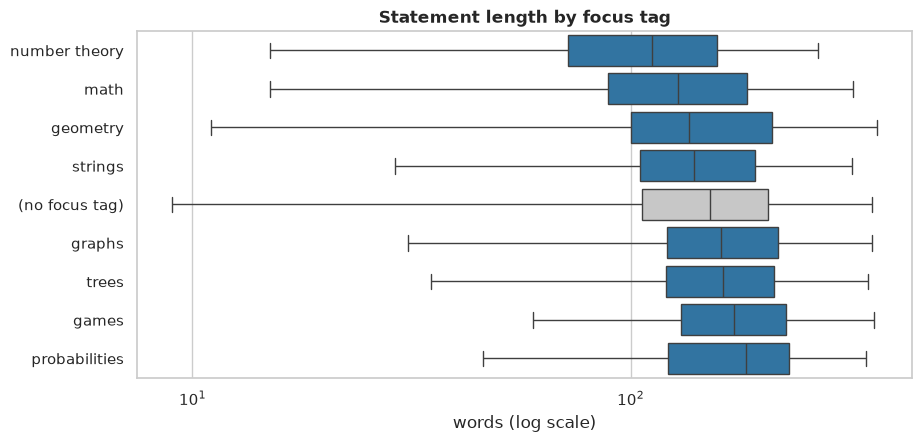

In [27]:
ax = boxplot_by_label(statement_words["description"], focus, log=True, none_label=NO_FOCUS)
ax.set(title="Statement length by focus tag", xlabel="words (log scale)")
plt.show()

Median statement length runs from about 110 words (`number theory`) to 180
(`probabilities`, `games`), with heavily overlapping distributions. Length is not a
useful feature on its own.

### 7.2 Words that signal each focus tag

For each focus tag, the statement words (description + input/output spec, math removed)
that best separate problems with the tag from problems without it.
`distinctive_terms()` builds the 2×2 table "word present × tag present" for every word,
and ranks words by the z-score of the log odds ratio (OR). The z-score stops a word seen
in three statements from winning on chance. Words with OR < 2 are dropped, so large tags
are not topped by generic words. Only words in at least 10 statements are kept. This is a
quick check that the text carries signal, not a model.

In [28]:
statement = df["statement"]  # description + input spec + output spec
input_spec = df["prob_desc_input_spec"].fillna("")
output_spec = df["prob_desc_output_spec"].fillna("")

distinctive_terms(
    statement.map(strip_latex), focus[order], stop_words="english",
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
)  # fmt: skip

,math,graphs,strings,number theory,trees,geometry,games,probabilities
rank,,,,,,,,
1,test (OR 2.2),connected (OR 16.2),letters (OR 37.7),divisor (OR 62.2),tree (OR 97.8),plane (OR 56.5),optimally (OR 170.1),probability (OR 301.3)
2,cases (OR 2.2),graph (OR 17.6),lowercase (OR 35.9),greatest (OR 40.0),connected (OR 20.6),coordinates (OR 32.3),players (OR 117.8),expected (OR 178.0)
3,divisible (OR 5.5),edge (OR 12.2),string (OR 34.6),common (OR 10.2),vertices (OR 20.9),point (OR 19.9),player (OR 120.8),random (OR 35.2)
4,modulo (OR 3.0),edges (OR 13.8),strings (OR 21.9),divisible (OR 9.8),edge (OR 20.2),points (OR 19.7),turns (OR 80.9),error (OR 20.7)
5,divisor (OR 7.1),vertices (OR 10.2),english (OR 25.0),prime (OR 33.5),edges (OR 21.5),error (OR 18.9),wins (OR 101.2),fraction (OR 66.3)
6,greatest (OR 4.9),undirected (OR 15.0),latin (OR 17.0),gcd (OR 72.5),vertex (OR 24.2),absolute (OR 12.4),loses (OR 92.4),relative (OR 18.5)
7,remainder (OR 4.3),vertex (OR 10.0),substring (OR 19.1),positive (OR 3.7),path (OR 18.6),relative (OR 16.0),play (OR 81.5),randomly (OR 50.2)
8,prime (OR 5.4),pair (OR 4.8),length (OR 8.0),divisors (OR 40.8),graph (OR 17.2),polygon (OR 75.3),turn (OR 43.5),real (OR 17.6)
9,gcd (OR 5.6),path (OR 6.4),characters (OR 6.2),product (OR 9.3),undirected (OR 20.1),coordinate (OR 10.1),win (OR 39.2),irreducible (OR 110.8)


### 7.3 A time confound: `test` and `cases` as "math" words

`test` and `cases` top the `math` column, with a weak odds ratio. They come from the
input format "The first line contains $t$, the number of test cases", which Codeforces
adopted around 2019, when the share of `math` problems also rose (§5). How much of the
association is just the period? The table compares math rates within each year, and the
Mantel–Haenszel odds ratio pools those within-year comparisons.

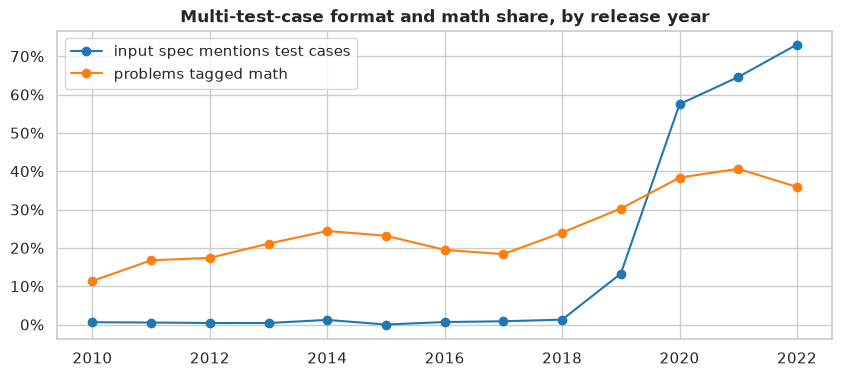

,P(math | multi-test),P(math | single test),multi-test problems
prob_desc_created_at,,,
2019,0.37,0.29,79
2020,0.45,0.29,357
2021,0.45,0.33,410
2022,0.36,0.35,458


Odds ratio multi-test -> math: crude 2.31, within year 1.57


In [29]:
multi_test = input_spec.str.contains("test case", case=False)
is_math = focus["math"] == 1

trends = pd.DataFrame(
    {
        "input spec mentions test cases": multi_test.groupby(year).mean(),
        "problems tagged math": is_math.groupby(year).mean(),
    }
)
ax = trends.plot(marker="o", figsize=(10, 4))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(title="Multi-test-case format and math share, by release year", xlabel="", ylabel="")
plt.show()


recent = year >= 2019
display(
    pd.DataFrame(
        {
            "P(math | multi-test)": is_math[multi_test & recent].groupby(year).mean(),
            "P(math | single test)": is_math[~multi_test & recent].groupby(year).mean(),
            "multi-test problems": multi_test[recent].groupby(year).sum(),
        }
    ).round(2)
)
print(f"Odds ratio multi-test -> math: crude {odds_ratio(multi_test, is_math):.2f}, "
      f"within year {odds_ratio(multi_test, is_math, year):.2f}")  # fmt: skip

Part of the association is the period, but not all of it. Within the same year, multi-test
problems are still more often `math`, mostly among easy problems where formula-style
tasks are common. A split by release date would show how much a model relies on this.

### 7.4 Inside the math spans

§7.2 removed the `$$$…$$$` spans, yet they hold strong cues: the `998244353` modulus of
probability problems, `\gcd`, or `n-1` edges for trees. The same ranking, applied to
the contents of the math spans only:

In [30]:
math_only = statement.map(lambda text: " ".join(math_spans(text)))
distinctive_terms(math_only, focus[order], token_pattern=r"\\?[A-Za-z]+|\d+")

,math,graphs,strings,number theory,trees,geometry,games,probabilities
rank,,,,,,,,
1,10 (OR 2.5),u (OR 10.6),s (OR 7.7),gcd (OR 48.8),v (OR 22.3),y (OR 3.9),101 (OR 13.8),\equiv (OR 94.9)
2,9 (OR 2.5),v (OR 8.2),26 (OR 7.5),\gcd (OR 65.2),u (OR 22.2),\max (OR 4.2),\textbf (OR 13.8),\pmod (OR 110.6)
3,t (OR 2.2),m (OR 2.9),\texttt (OR 10.0),18 (OR 4.4),\ne (OR 6.2),90 (OR 12.1),\not (OR 6.3),\not (OR 89.2)
4,1 (OR 2.2),\neq (OR 4.7),50 (OR 2.4),10 (OR 2.2),\neq (OR 5.9),max (OR 4.6),\pmod (OR 6.3),998244353 (OR 17.0)
5,x (OR 2.1),\ne (OR 3.8),5000 (OR 2.5),x (OR 2.3),w (OR 3.8),\frac (OR 2.0),\equiv (OR 5.5),\frac (OR 8.4)
6,7 (OR 2.3),w (OR 4.1),\rightarrow (OR 3.6),lcm (OR 52.9),p (OR 2.2),ox (OR 4.4),\bmod (OR 3.3),\bmod (OR 16.4)
7,18 (OR 3.2),min (OR 4.2),\text (OR 3.1),\bmod (OR 5.0),f (OR 3.0),200000 (OR 5.8),z (OR 3.8),p (OR 4.8)
8,\frac (OR 2.4),e (OR 4.7),3000 (OR 2.5),12 (OR 3.6),y (OR 2.0),\color (OR 4.6),\times (OR 2.3),q (OR 4.0)
9,\bmod (OR 4.4),\min (OR 2.5),\dagger (OR 2.6),y (OR 2.0),e (OR 5.1),\mathrm (OR 4.1),ij (OR 4.4),\mod (OR 16.6)


In [31]:
cues = {
    "modulus 998244353 or 10^9+7": r"998\s*244\s*353|10\^\{?9\}?\s*\+\s*7",
    r"\gcd or lcm": r"\\gcd|lcm",
    "n - 1 (edges of a tree)": r"n\s*-\s*1",
    r"\frac (fraction)": r"\\frac",
}
cue_present = pd.DataFrame(
    {name: math_only.str.contains(pattern) for name, pattern in cues.items()}
)
summarise_by_label(cue_present, focus[order]).map("{:.0%}".format)

,math,graphs,strings,number theory,trees,geometry,games,probabilities,all problems
modulus 998244353 or 10^9+7,6%,3%,2%,5%,4%,3%,4%,25%,3%
\gcd or lcm,2%,0%,0%,7%,0%,0%,1%,2%,1%
n - 1 (edges of a tree),11%,21%,4%,11%,44%,6%,11%,12%,10%
\frac (fraction),8%,7%,3%,8%,5%,9%,5%,28%,5%


Math spans should be kept (and normalised) rather than removed: they carry some of the
most specific cues in the statement.

### 7.5 Sample I/O and output format

The examples and the output specification give cheap, high-precision cues for some of
the rarest focus tags. Share of problems with each cue:

In [32]:
outputs = df["prob_desc_sample_outputs"].map("\n".join, na_action="ignore").fillna("")
player = r"\b(?:Alice|Bob|First|Second|Draw|Petya|Vasya)\b"
tolerance = r"(?:absolute\s+or\s+relative|relative\s+or\s+absolute)\s+error"
io_cues = pd.DataFrame(
    {
        "sample output names a player": outputs.str.contains(player),
        "sample output has a decimal number": outputs.str.contains(r"\d\.\d"),
        "sample output is only YES/NO": outputs.str.fullmatch(r"(?:\s*(?:yes|no)\s*)+", case=False),
        "output spec: absolute or relative error": output_spec.str.contains(tolerance, case=False),
    }
)
summarise_by_label(io_cues, focus[order]).map("{:.0%}".format)

,math,graphs,strings,number theory,trees,geometry,games,probabilities,all problems
sample output names a player,1%,0%,1%,1%,1%,0%,20%,0%,1%
sample output has a decimal number,5%,1%,1%,1%,3%,31%,1%,42%,3%
sample output is only YES/NO,9%,6%,14%,10%,6%,10%,7%,1%,8%
output spec: absolute or relative error,4%,1%,0%,1%,2%,25%,0%,32%,2%


### 7.6 Input length for transformer encoders

If a pretrained encoder (CodeBERT, UniXcoder…) is considered, its 512-token window
matters. A rough proxy counts words, numbers and punctuation symbols separately, with
LaTeX kept. Subword tokenizers split further, so real token counts are higher.

In [33]:
lengths = pd.DataFrame(
    {
        "statement": statement.map(approximate_token_count),
        "code": df["source_code"].map(approximate_token_count),
    }
)
lengths["statement + code"] = lengths.sum(axis=1)
length_summary = lengths.quantile([0.5, 0.9]).T.rename(columns={0.5: "median", 0.9: "p90"})
length_summary["share > 512"] = (lengths > 512).mean().map("{:.0%}".format)
length_summary["share > 1024"] = (lengths > 1024).mean().map("{:.0%}".format)
length_summary

,median,p90,share > 512,share > 1024
statement,424.0,719.9,33%,1%
code,253.0,853.9,21%,7%
statement + code,722.0,1440.9,76%,24%


## 8. Solution code

### 8.1 Runtime and length

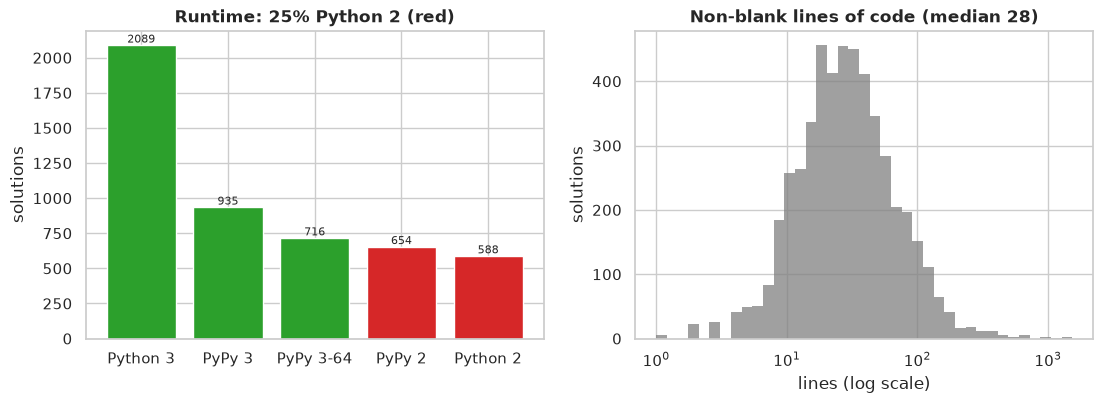

,count,mean,std,min,5%,50%,95%,max
lines,4982.0,43.0,66.0,1.0,7.0,28.0,119.0,1541.0


In [34]:
code_lines = df["source_code"].map(code_line_count)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lang_counts = df["lang"].value_counts()
colors = [
    "tab:red" if python_major_version(lang) == 2 else "tab:green" for lang in lang_counts.index
]
axes[0].bar_label(axes[0].bar(lang_counts.index, lang_counts.values, color=colors), fontsize=8)
python2_share = (python_major == 2).mean()
axes[0].set(title=f"Runtime: {python2_share:.0%} Python 2 (red)", xlabel="", ylabel="solutions")
bins = np.logspace(0, np.log10(code_lines.max()), 40)
sns.histplot(code_lines, bins=bins, color="grey", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set(title=f"Non-blank lines of code (median {code_lines.median():.0f})")
axes[1].set(xlabel="lines (log scale)", ylabel="solutions")
plt.show()
code_lines.describe(percentiles=[0.05, 0.5, 0.95]).round(0).to_frame("lines").T

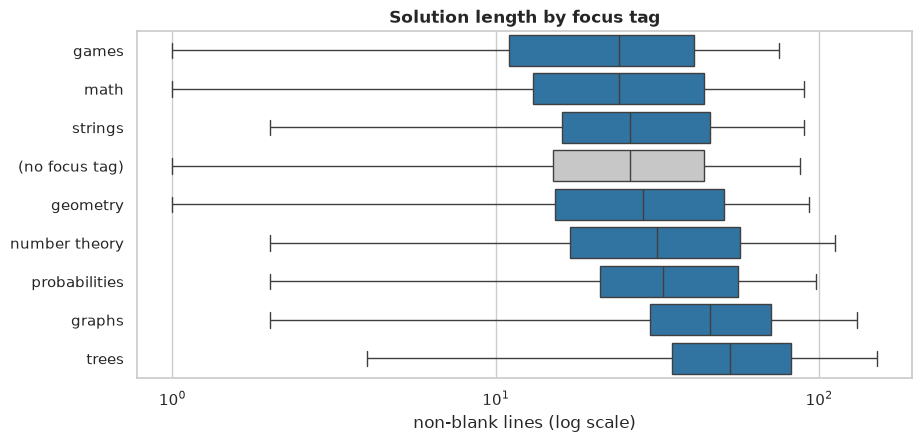

label,math,graphs,strings,number theory,trees,geometry,games,probabilities,(no focus tag)
median lines,24.0,46.0,26.0,31.5,53.0,28.5,24.0,33.0,26.0


In [35]:
ax = boxplot_by_label(code_lines, focus, log=True, none_label=NO_FOCUS)
ax.set(title="Solution length by focus tag", xlabel="non-blank lines (log scale)")
plt.show()
by_tag = values_by_label(code_lines, focus, none_label=NO_FOCUS)
median_lines = by_tag.groupby("label")["value"].median().loc[[*order, NO_FOCUS]]
median_lines.to_frame("median lines").T

Solutions to `trees` and `graphs` problems are clearly longer than the others: building
an adjacency list and a traversal takes code. Code length is a weak structural feature.

### 8.2 Imports

Code features cannot rely on Python 3's `ast` module: every solution that fails to
parse is Python 2 code.

In [36]:
parses = df["source_code"].map(parses_as_python3)
runtime = python_major.map({2: "Python 2", 3: "Python 3"}).rename("runtime")
outcome = parses.map({True: "parses", False: "fails"}).rename("ast.parse")
display(pd.crosstab(runtime, outcome, margins=True))
print(f"{(~parses).mean():.1%} of solutions do not parse with Python 3's ast")

ast.parse,fails,parses,All
runtime,,,
Python 2,925,317,1242
Python 3,0,3740,3740
All,925,4057,4982


18.6% of solutions do not parse with Python 3's ast


Imports are therefore read with a regex. Part of them come from copy-pasted fast-I/O
templates (`os`, `io`, `atexit`, `__pypy__`) rather than from the algorithm.

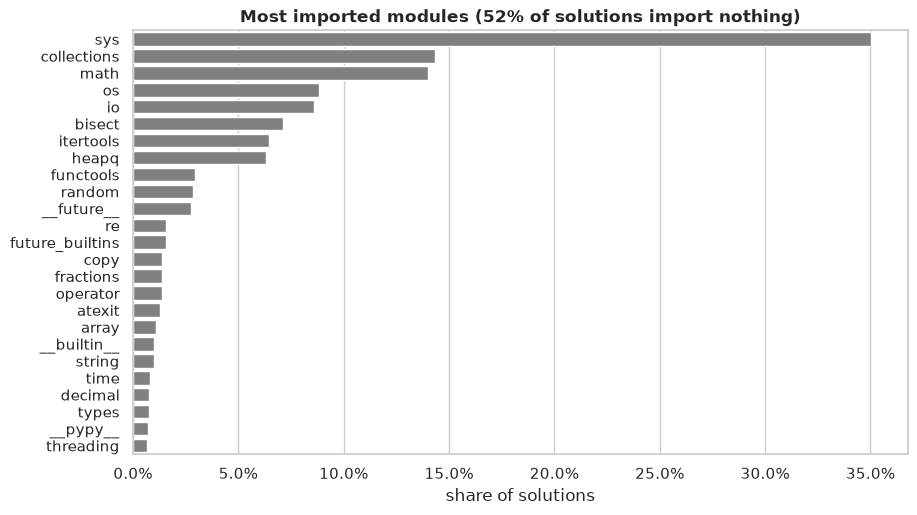

In [37]:
imports = df["source_code"].map(imported_modules)
module_counts = label_counts(imports)
import_share = module_counts / len(df)

fig, ax = plt.subplots(figsize=(10, 5.5))
top_imports = import_share.head(25)
sns.barplot(x=top_imports.values, y=top_imports.index, color="grey", ax=ax)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
no_import = (imports.str.len() == 0).mean()
ax.set(title=f"Most imported modules ({no_import:.0%} of solutions import nothing)")
ax.set(xlabel="share of solutions", ylabel="")
plt.show()

**Lift between imports and focus tags**: P(tag | the solution imports the module) / P(tag),
for modules imported by at least 40 solutions (count in brackets). Colour is on a log2
scale, so halving and doubling look equally strong. Cells backed by fewer than 5 problems
are left blank.

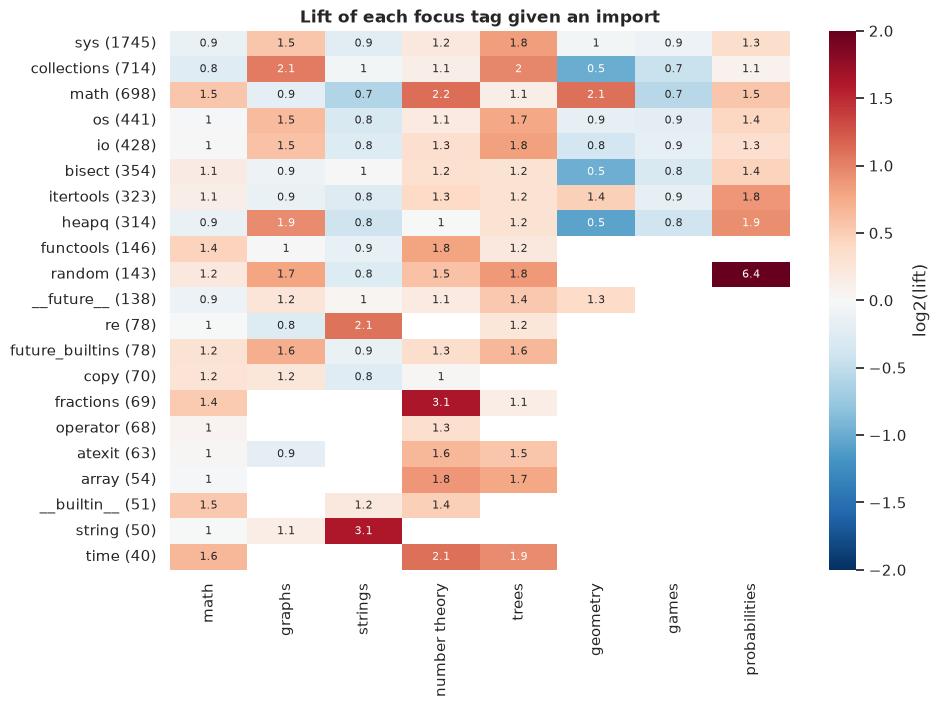

In [38]:
frequent_modules = import_share[module_counts[import_share.index] >= 40].index
uses_module = multi_hot(imports, vocabulary=frequent_modules)
both = cooccurrence(uses_module, focus)[order]
module_lift = lift(uses_module, focus)[order]

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    np.log2(module_lift.clip(lower=1 / 8)), mask=both < 5, annot=module_lift.round(1), fmt="g",
    cmap="RdBu_r", center=0, vmin=-2, vmax=2, cbar_kws={"label": "log2(lift)"},
    annot_kws={"fontsize": 8}, ax=ax,
)  # fmt: skip
ax.grid(False)
ax.set_yticklabels([f"{module} ({uses_module[module].sum()})" for module in module_lift.index])
ax.set(title="Lift of each focus tag given an import", xlabel="", ylabel="")
plt.show()

### 8.3 Identifiers that signal each focus tag

The same ranking as for the statement, applied to the tokens of the solution
(identifiers, function names, keywords of 3+ characters). Some top tokens are personal
helper names (`int_mulmod`, `intop`): a handful of authors reuse the same template, which
a model can memorise.

In [39]:
distinctive_terms(
    df["source_code"], focus[order], token_pattern=r"(?u)\b[A-Za-z_][A-Za-z0-9_]{2,}\b"
)

,math,graphs,strings,number theory,trees,geometry,games,probabilities
rank,,,,,,,,
1,pow (OR 3.1),append (OR 5.5),ord (OR 7.5),gcd (OR 6.7),pop (OR 6.3),points (OR 29.8),bob (OR 83.6),pow (OR 8.0)
2,gcd (OR 2.2),not (OR 3.7),len (OR 3.2),math (OR 3.0),node (OR 12.1),eps (OR 25.2),alice (OR 140.4),random (OR 7.5)
3,primes (OR 3.5),while (OR 3.9),chr (OR 6.1),primes (OR 13.4),parent (OR 21.0),cross (OR 41.1),win (OR 63.0),int_mulmod (OR 56.5)
4,decimal (OR 3.1),pop (OR 4.0),replace (OR 6.2),prime (OR 7.4),append (OR 8.2),point (OR 16.6),second (OR 16.9),prob (OR 66.7)
5,prime (OR 2.6),edges (OR 22.5),text (OR 13.6),pow (OR 3.9),dfs (OR 10.9),cos (OR 16.6),game (OR 13.6),intop (OR 48.9)
6,inv (OR 2.8),continue (OR 3.3),char (OR 9.4),factor (OR 17.1),root (OR 13.6),abs (OR 3.8),first (OR 4.7),__pypy__ (OR 12.0)
7,lru_cache (OR 2.4),visited (OR 15.0),string (OR 2.8),sieve (OR 11.1),stack (OR 7.8),sqrt (OR 4.6),odd (OR 5.6),exp (OR 23.6)
8,fact (OR 2.8),popleft (OR 8.4),ascii_lowercase (OR 8.6),factors (OR 9.9),sys (OR 3.6),dist (OR 5.8),makes (OR 8.5),mult (OR 21.6)
9,comment (OR 3.9),stack (OR 6.6),lower (OR 5.6),return (OR 2.1),stdin (OR 3.3),math (OR 2.6),off (OR 12.4),tmp (OR 5.9)


## 9. Key takeaways

**The data**

1. **One accepted Python solution per problem, with no exact duplicates, but some near-duplicates.**
   - 82 pairs of statements (164 problems, 3.3%) are near-duplicates, mostly the easy and hard versions of the same problem (§2.6). Two LLM judges confirmed them among TF-IDF candidates; the audit is in `02_near_duplicates.ipynb`.
   - Only 19 of these pairs share the exact same tags, while 69 share the same focus tags.
   - Splits must keep each pair together, using the groups from `near_duplicate_groups()`.
2. **Several variables carry no information or must not be used as features:**
   - `exec_outcome`, `lang_cluster` and `hidden_unit_tests` are constant;
   - `prob_desc_input_from` and `prob_desc_output_to` are nearly constant;
   - `src_uid`, `code_uid` and `file_name` are identifiers;
   - `difficulty` is a post-contest rating (see 9).
3. **41 problems (0.8%) have no tags.** They stay in the dataset as problems with none of the tags. Some are clearly about trees or games, so their labels may be incomplete: check the model's errors on them. Other missing values:
   - notes: 27%;
   - output spec: 1.7%;
   - input spec: 0.7%;
   - difficulty: 1.1% (39 `None` + 15 `-1`).
4. **The text needs light, targeted cleaning:**
   - 86% of statements have paragraphs glued together (`instead.You`);
   - every notes field starts with a section heading ("Note", or "Примечание" in Russian), glued to the text in 98.7% of them;
   - 17 statements (0.3%) are in Russian, and they are exactly the 17 problems whose limits are in Russian;
   - a few English statements contain Cyrillic look-alike letters (`simplе`).

   The `$$$…$$$` math spans (56% of statements) should be kept and normalised, not removed (see 12).
5. **A quarter of the solutions (24.9%) are Python 2:** 46% for 2011–2013 problems, 2% from 2021. 18.6% of solutions do not parse with Python 3's `ast`, all of them Python 2, so code features must not depend on it.

**The target**

6. **The task is genuinely multi-label.** There are 37 tags, 2.8 per problem on average, forming 1,722 distinct tag sets (the empty set included). Six of these tags (e.g. `hashing`, `*special`) are missing from the xCodeEval paper's tag figure.
7. **The focus tags are imbalanced:** from `math` (28.3%) down to `probabilities` (1.8%), a 15× gap.
   - 46.2% of problems have none of the 8 focus tags, so "no focus tag" must be a normal prediction.
   - 13.2% have two or more focus tags.
   - `games` (105) and `probabilities` (92) have about 100 positives each, so a 20% test split leaves about 20 of each. Per-tag scores need cross-validation or bootstrap intervals.
8. **Tags overlap heavily.** Among problems with the row tag:
   - `number theory` → `math`: 75%; `probabilities` → `math`: 49%;
   - `trees` → `dfs and similar`: 65%, and → `graphs`: 38%;
   - `graphs` → `dfs and similar`: 56%.

   Errors will be correlated across tags. Joint models (e.g. classifier chains) or non-focus tags as auxiliary targets could help.
9. **Difficulty is informative for some tags but is set after the contest.**
   - On its own it separates `probabilities` (AUC 0.79), `trees` (0.72) and `graphs` (0.70) well, but not `math` (0.47) or `strings` (0.44), which lean towards easier problems.
   - Tags per problem grow with difficulty, from 2.05 to 3.35.
   - Use it only if the test exercises come with a rating, and add a missing-value indicator.
10. **The tag mix drifts over time.** The share of `math` went from 19.4% (up to 2017) to 36.4% (2019 and later). At the same time the multi-test-case input format spread (§7.3).
    - Only part of the "test cases" → `math` association is that shared period: the odds ratio is 2.31 overall and 1.57 within the same year.
    - A date-based holdout would show how much a model relies on this.

**Where the signal is**

11. **The statement words are strongly tag-specific.** Odds ratios of the strongest words:
    - `probabilities`: *probability* (301), *expected* (178);
    - `games`: *optimally* (170), *player* (121);
    - `trees`: *tree* (98), *root* (49);
    - `number theory`: *gcd* (72), *divisor* (62);
    - `geometry`: *polygon* (75), *plane* (56).

    A TF-IDF + linear model should make a strong first baseline.
12. **The math spans carry specific cues:**
    - `\pmod`, `\equiv` and the `998244353` / `10^9+7` modulus point to `probabilities` (the modulus appears in 25% of them vs 3% overall);
    - `\gcd` / `lcm` point to `number theory`;
    - `n - 1` appears in 44% of `trees` statements vs 10% overall.
13. **Sample I/O and the output spec give cheap, precise cues for rare tags:**
    - a sample output naming a player: 20% of `games` vs 1% overall;
    - a decimal number in the sample output: 31% of `geometry` and 42% of `probabilities` vs 3% overall;
    - "absolute or relative error" in the output spec: 25% and 32% vs 2% overall.
14. **The code adds complementary signal.**
    - Identifiers: *primes, sieve, factor* (`number theory`), *edges, visited, dfs* (`graphs`), *alice, bob* (`games`), *cross, eps, points* (`geometry`).
    - Imports: `random` → `probabilities` (lift 6.4), `fractions` → `number theory` and `string` → `strings` (about 3), `re` → `strings` and `collections`/`heapq` → `graphs` (about 2).
    - Length: `trees` and `graphs` solutions are about twice as long as those of problems without a focus tag (median 53 and 46 lines vs 26).
    - Noise: copy-pasted fast-I/O templates, and personal helper names (`int_mulmod`) that a model could memorise.
15. **Inputs are long for 512-token encoders.** Statement + code exceeds 512 pieces for 76% of problems, even with a word-level proxy. A transformer needs a truncation strategy; TF-IDF does not.

**Next steps**

- Build a split that keeps near-duplicate pairs together and stratifies on the labels.
- Train a TF-IDF baseline on the statement (LaTeX normalised), code tokens and sample-output cues, with one-vs-rest linear models and per-tag thresholds.
- Report per-tag F1 plus macro and micro F1, with bootstrap intervals.